# Dry Bean Multi-Class Classification using Random Forest Classifier

## Project Introduction

This project aims to classify dry bean varieties into seven different classes using the Random Forest Classifier algorithm.

The dataset contains 16 numerical features describing the shape and size of dry beans, such as Area, Perimeter, Major Axis Length, and Minor Axis Length.

The Random Forest algتorithm will be trained to predict the bean variety based on these features.

## Project Objectives

- Explore and understand the Dry Bean dataset.
- Prepare the data for classification.
- Build a Random Forest Classification model.
- Evaluate the model using Accuracy, Weighted Precision, Weighted Recall, Weighted F1-Score, and Log Loss.

In [40]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    log_loss,
    confusion_matrix,
    classification_report
)

import warnings
warnings.filterwarnings('ignore')

In [41]:
import os

for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/datasets/muratkokludataset/dry-bean-dataset/Dry_Bean_Dataset/Dry_Bean_Dataset.arff
/kaggle/input/datasets/muratkokludataset/dry-bean-dataset/Dry_Bean_Dataset/Dry_Bean_Dataset.xlsx
/kaggle/input/datasets/muratkokludataset/dry-bean-dataset/Dry_Bean_Dataset/Dry_Bean_Dataset_Citation_Request.txt


# Dataset Loading

In this step, we load the Dry Bean dataset from an Excel file using Pandas.

The dataset is stored in a DataFrame named `df`. We then display its dimensions and the first five rows to get an initial look at the data.

In [42]:
df = pd.read_excel(
    '/kaggle/input/datasets/muratkokludataset/dry-bean-dataset/Dry_Bean_Dataset/Dry_Bean_Dataset.xlsx'
)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (13611, 17)


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


# Dataset Inspection and Quality Analysis

In this step, we inspect the dataset to understand its structure and data quality.

We use the following functions:

- `df.info()` to examine column names, data types, and non-null values.
- `df.isnull().sum()` to identify missing values.
- `df.duplicated().sum()` to detect duplicate rows.
- `df.describe()` to display statistical summaries of numerical features.

In [43]:
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nStatistical Summary:")
df.describe()

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13611 non-null  int64  
 1   Perimeter        13611 non-null  float64
 2   MajorAxisLength  13611 non-null  float64
 3   MinorAxisLength  13611 non-null  float64
 4   AspectRation     13611 non-null  float64
 5   Eccentricity     13611 non-null  float64
 6   ConvexArea       13611 non-null  int64  
 7   EquivDiameter    13611 non-null  float64
 8   Extent           13611 non-null  float64
 9   Solidity         13611 non-null  float64
 10  roundness        13611 non-null  float64
 11  Compactness      13611 non-null  float64
 12  ShapeFactor1     13611 non-null  float64
 13  ShapeFactor2     13611 non-null  float64
 14  ShapeFactor3     13611 non-null  float64
 15  ShapeFactor4     13611 non-null  float64
 16  Class            13611 non-null  obje

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
count,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000
mean,53048.284549,855.283459,320.141867,202.270714,1.583242,0.750895,53768.200206,253.064220,0.749733,0.987143,0.873282,0.799864,0.006564,0.001716,0.643590,0.995063
std,29324.095717,214.289696,85.694186,44.970091,0.246678,0.092002,29774.915817,59.177120,0.049086,0.004660,0.059520,0.061713,0.001128,0.000596,0.098996,0.004366
min,20420.000000,524.736000,183.601165,122.512653,1.024868,0.218951,20684.000000,161.243764,0.555315,0.919246,0.489618,0.640577,0.002778,0.000564,0.410339,0.947687
25%,36328.000000,703.523500,253.303633,175.848170,1.432307,0.715928,36714.500000,215.068003,0.718634,0.985670,0.832096,0.762469,0.005900,0.001154,0.581359,0.993703
50%,44652.000000,794.941000,296.883367,192.431733,1.551124,0.764441,45178.000000,238.438026,0.759859,0.988283,0.883157,0.801277,0.006645,0.001694,0.642044,0.996386
75%,61332.000000,977.213000,376.495012,217.031741,1.707109,0.810466,62294.000000,279.446467,0.786851,0.990013,0.916869,0.834270,0.007271,0.002170,0.696006,0.997883
max,254616.000000,1985.370000,738.860153,460.198497,2.430306,0.911423,263261.000000,569.374358,0.866195,0.994677,0.990685,0.987303,0.010451,0.003665,0.974767,0.999733


# Data Cleaning

In this step, we remove duplicate rows from the dataset to avoid repeated samples.

The `drop_duplicates()` function is used to remove duplicate records. We then compare the dataset dimensions before and after cleaning and verify that no duplicate rows remain.

In [44]:
print("Shape Before Cleaning:", df.shape)

df = df.drop_duplicates()

print("Shape After Cleaning:", df.shape)

print("Remaining Duplicates:", df.duplicated().sum())

Shape Before Cleaning: (13611, 17)
Shape After Cleaning: (13543, 17)
Remaining Duplicates: 0


# Exploratory Data Analysis (EDA)

### Class Distribution

In this step, we analyze the distribution of the seven dry bean classes.

The number of samples in each class is calculated using `value_counts()`, and a count plot is used to visualize the distribution.

This analysis helps us understand whether the dataset is balanced or imbalanced.

Number of Samples in Each Class:
Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1860
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64


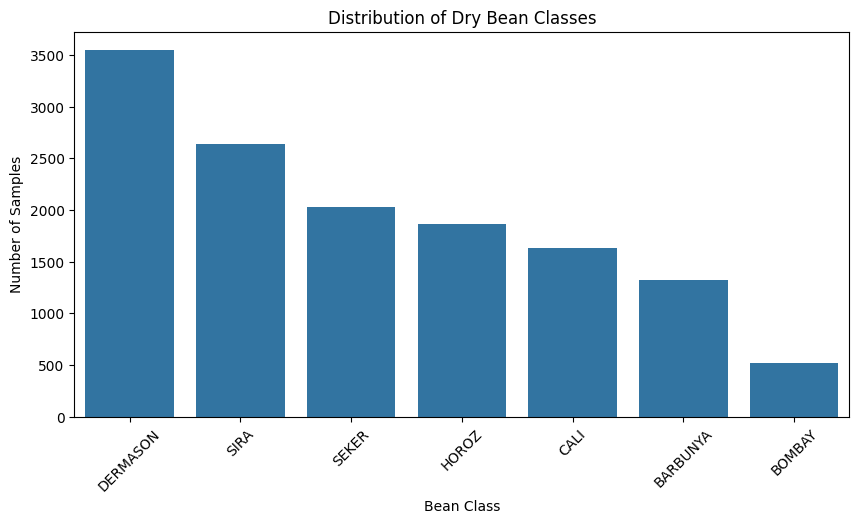

In [45]:
print("Number of Samples in Each Class:")
print(df['Class'].value_counts())

plt.figure(figsize=(10, 5))

sns.countplot(data=df, x='Class', order=df['Class'].value_counts().index)

plt.title('Distribution of Dry Bean Classes')
plt.xlabel('Bean Class')
plt.ylabel('Number of Samples')
plt.xticks(rotation=45)

plt.show()

# Feature Distribution

In this step, we explore the distribution of numerical features in the dataset using histograms.

Histograms help us understand how feature values are distributed and identify patterns such as skewness and variations in the data.

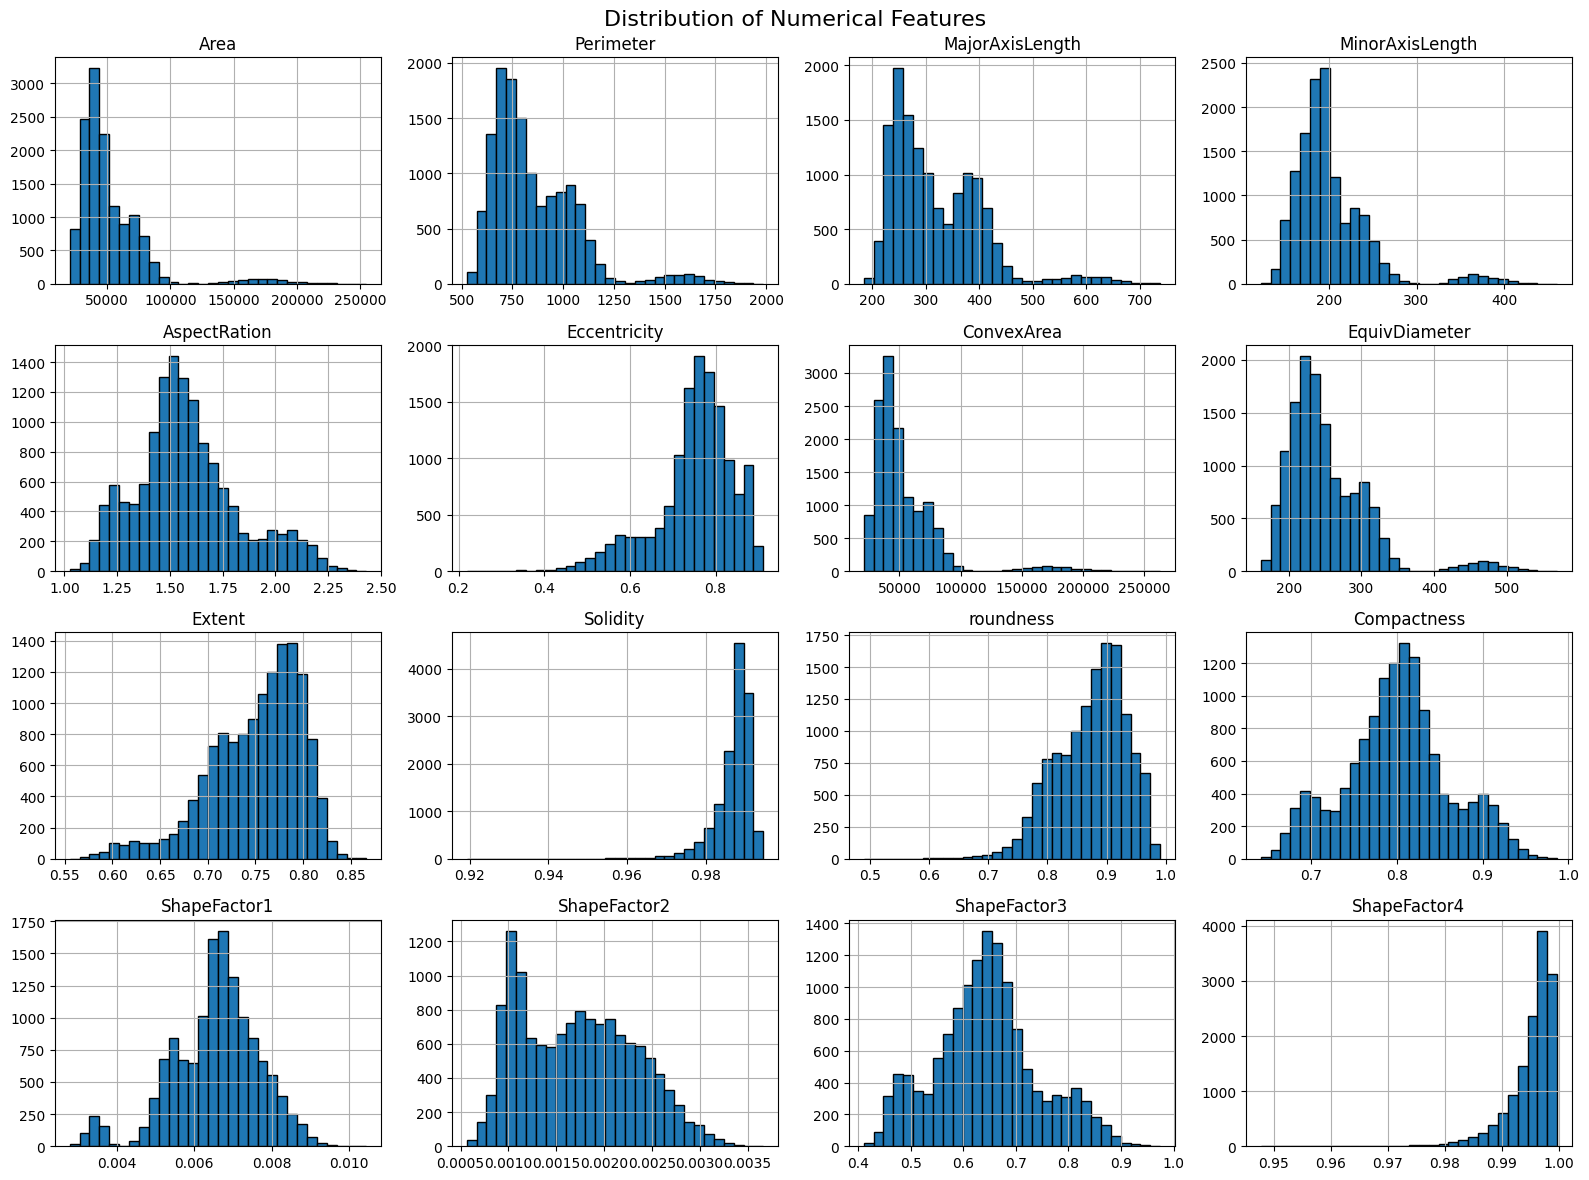

In [46]:
df.hist(figsize=(16, 12), bins=30, edgecolor='black')

plt.suptitle('Distribution of Numerical Features', fontsize=16)

plt.tight_layout()
plt.show()

# Correlation Analysis

In this step, we examine the correlation between numerical features using a correlation matrix.

A heatmap is used to visualize the relationships between features and identify strongly correlated variables.

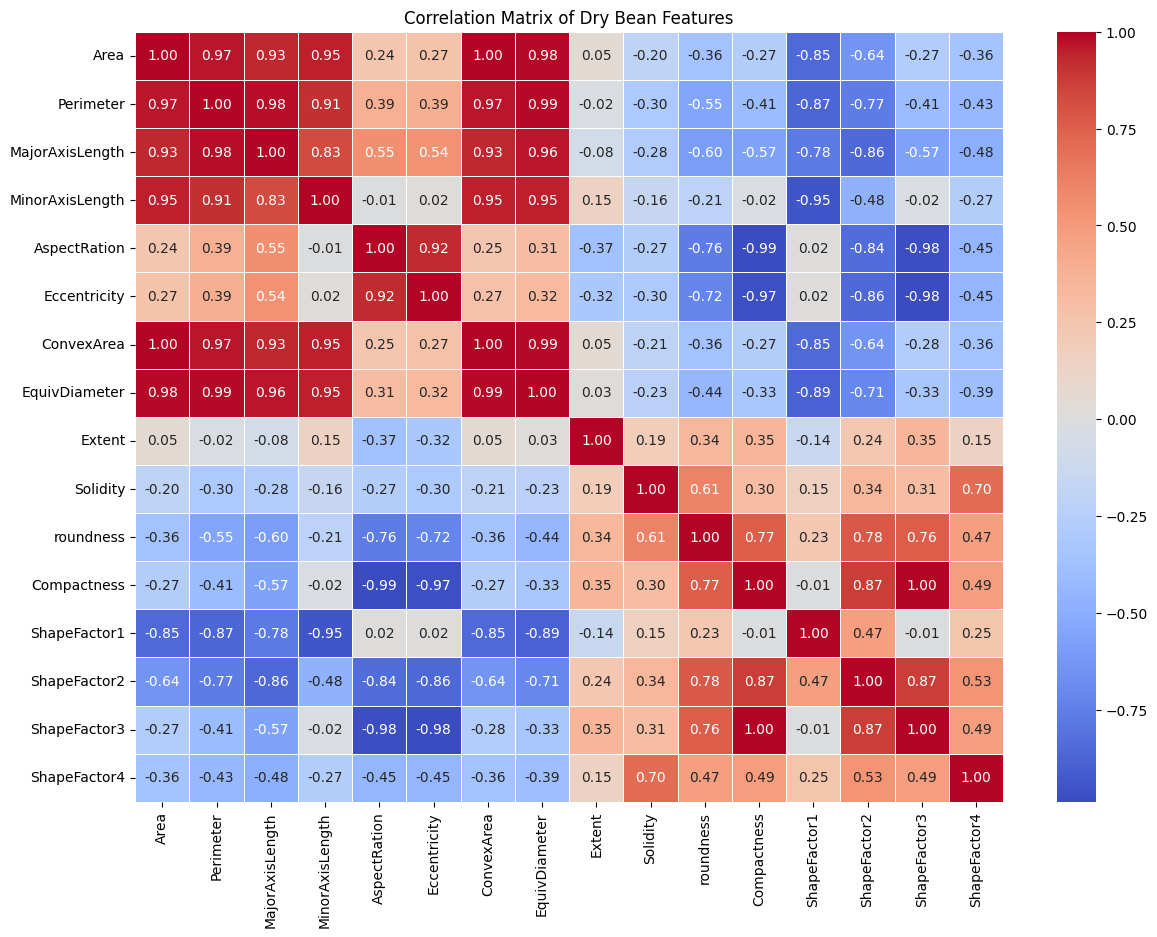

In [47]:
plt.figure(figsize=(14, 10))

correlation_matrix = df.drop(columns=['Class']).corr()

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Matrix of Dry Bean Features')
plt.show()

# Data Preparation

In this step, we separate the input features from the target variable.

The 16 numerical features will be used as inputs to train the Random Forest model, while the Class column represents the target variable that the model aims to predict.

In [48]:
X = df.drop('Class', axis=1)
y = df['Class']

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)
print("Target Classes:", y.unique())

Features Shape: (13543, 16)
Target Shape: (13543,)
Target Classes: ['SEKER' 'BARBUNYA' 'BOMBAY' 'CALI' 'HOROZ' 'SIRA' 'DERMASON']


# Data Splitting

In this step, we split the dataset into training, validation, and testing sets.

We use 70% of the data for training, 15% for validation, and 15% for testing.

Stratified sampling is applied to maintain the same class distribution across all three sets.

The `random_state` parameter ensures reproducibility of the results.

In [49]:

from sklearn.model_selection import train_test_split

# Split the data into 70% training and 30% temporary data
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Split the temporary data into 15% validation and 15% testing
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Testing set:", X_test.shape)


Training set: (9480, 16)
Validation set: (2031, 16)
Testing set: (2032, 16)


# Random Forest Classifier

Random Forest is an ensemble learning algorithm that combines multiple decision trees to improve classification performance.

Each tree makes a prediction, and the final class is determined through majority voting.

In this project, we use Random Forest to classify dry beans into seven different categories.

# Model Training

In [55]:

from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Model training completed successfully.")


Model training completed successfully.


# Model Validation

In this step, we evaluate the trained Random Forest model using the validation dataset.

The validation data helps us assess the model's performance on unseen data and determine whether its current settings are suitable before the final testing stage.

In [62]:

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

y_val_pred = rf_model.predict(X_val)

val_accuracy = accuracy_score(y_val, y_val_pred)
val_precision = precision_score(y_val, y_val_pred, average='weighted')
val_recall = recall_score(y_val, y_val_pred, average='weighted')
val_f1 = f1_score(y_val, y_val_pred, average='weighted')

print("Validation Accuracy:", round(val_accuracy, 4))
print("Validation Precision:", round(val_precision, 4))
print("Validation Recall:", round(val_recall, 4))
print("Validation F1-Score:", round(val_f1, 4))


Validation Accuracy: 0.9207
Validation Precision: 0.921
Validation Recall: 0.9207
Validation F1-Score: 0.9207


The validation results show that the Random Forest model achieved an accuracy of 92.07% and a weighted F1-score of 92.07%.

These results indicate that the model performs well on unseen validation data and provide an initial assessment of its classification performance before final testing.

# Model Prediction

After training, we use the trained model to predict the classes of the testing dataset.

We also calculate the predicted probabilities for each class, which are required to evaluate the model using Log Loss.

# Final Model Evaluation

In this step, we evaluate the final performance of the trained Random Forest model using the testing dataset.

The testing data was not used during model training or validation, providing an unbiased evaluation of the model's performance on unseen data.

In [52]:

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, log_loss

y_pred = rf_model.predict(X_test)
y_pred_proba = rf_model.predict_proba(X_test)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average='weighted')
recall = recall_score(y_test, y_pred, average='weighted')
f1 = f1_score(y_test, y_pred, average='weighted')
loss = log_loss(y_test, y_pred_proba)

print("Test Accuracy:", round(accuracy, 4))
print("Test Precision:", round(precision, 4))
print("Test Recall:", round(recall, 4))
print("Test F1-Score:", round(f1, 4))
print("Test Log Loss:", round(loss, 4))


Test Accuracy: 0.9203
Test Precision: 0.9201
Test Recall: 0.9203
Test F1-Score: 0.9202
Test Log Loss: 0.3689


The Random Forest model achieved a test accuracy of 92.03% and a weighted F1-score of 92.02%.

The validation and testing results are very close, indicating consistent model performance on unseen data.

The Log Loss value of 0.3689 also provides information about the quality of the predicted class probabilities.

# Evaluation Results Interpretation

The evaluation metrics measure the model's ability to correctly classify dry bean varieties.

Accuracy measures the overall percentage of correct predictions, while Weighted Precision, Weighted Recall, and Weighted F1-Score evaluate classification performance across all seven classes while considering their sample sizes.

Log Loss evaluates the quality of the predicted class probabilities. Lower Log Loss values indicate better probability predictions.

## Confusion Matrix

A Confusion Matrix is used to compare the actual classes with the predicted classes.

It helps identify the number of correct and incorrect predictions for each dry bean variety and shows which classes are confused with each other.

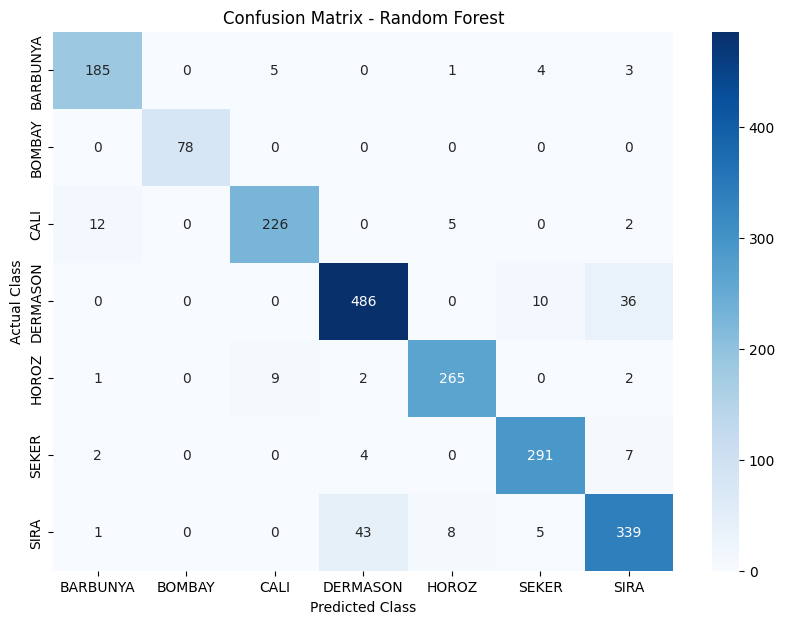

In [58]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=rf_model.classes_,
    yticklabels=rf_model.classes_
)

plt.title('Confusion Matrix - Random Forest')
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.show()

### Confusion Matrix Interpretation

The confusion matrix shows the classification results for each of the seven dry bean classes.

The diagonal cells represent correctly classified samples, while the off-diagonal cells represent misclassified samples.

# Feature Importance

Random Forest provides feature importance scores that indicate how much each feature contributes to the model's predictions.

In this step, we identify and visualize the most important features used for dry bean classification.

            Feature  Importance
14     ShapeFactor3    0.100957
12     ShapeFactor1    0.093023
1         Perimeter    0.089669
11      Compactness    0.083715
3   MinorAxisLength    0.078370
2   MajorAxisLength    0.077723
6        ConvexArea    0.071238
5      Eccentricity    0.065247
7     EquivDiameter    0.060338
4      AspectRation    0.060053
10        roundness    0.059958
0              Area    0.056327
13     ShapeFactor2    0.043810
15     ShapeFactor4    0.030775
9          Solidity    0.018202
8            Extent    0.010596


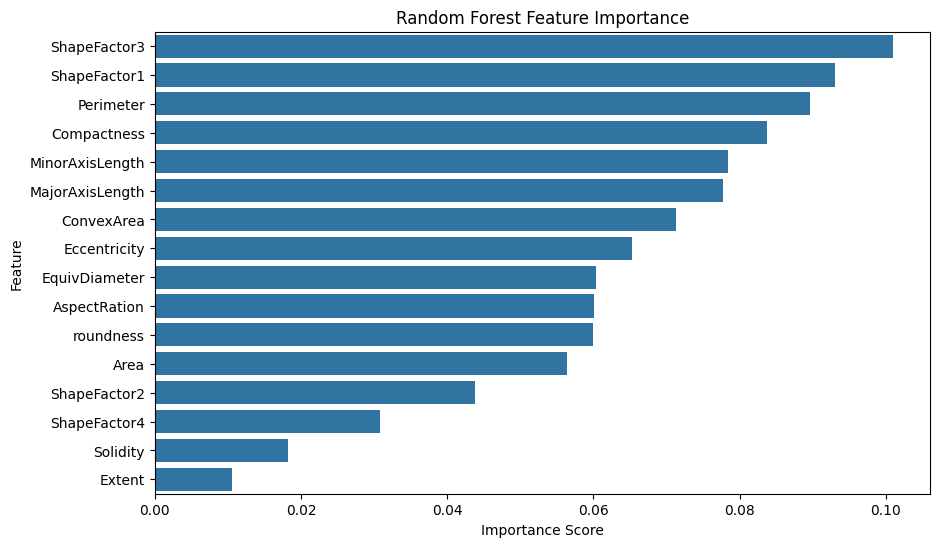

In [61]:
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print(feature_importance)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x='Importance',
    y='Feature'
)

plt.title('Random Forest Feature Importance')
plt.xlabel('Importance Score')
plt.ylabel('Feature')
plt.show()

# Conclusion

In this project, a Random Forest Classifier was developed to classify dry bean varieties into seven different classes using 16 numerical features.

The dataset was explored and cleaned by removing duplicate records. It was then divided into training, validation, and testing sets using a stratified splitting approach.

The model achieved a validation accuracy of 92.07% and a final test accuracy of 92.03%, with a weighted F1-score of 92.02%.

The confusion matrix was used to examine the classification results, while feature importance helped identify the most influential features.

Overall, the results demonstrate that Random Forest provides good performance in classifying dry bean varieties based on their physical characteristics.